In [46]:
import decimal

def load(path):
    df = pd.read_parquet(path)
    for c in df.columns:
        if df[c].dtype == object and df[c].dropna().map(type).eq(decimal.Decimal).any():
            df[c] = df[c].astype(float)
    return df

prop  = load("data/1_prepared_views/property_day.parquet")
daily = load("data/1_prepared_views/prepared_daily_view.parquet")

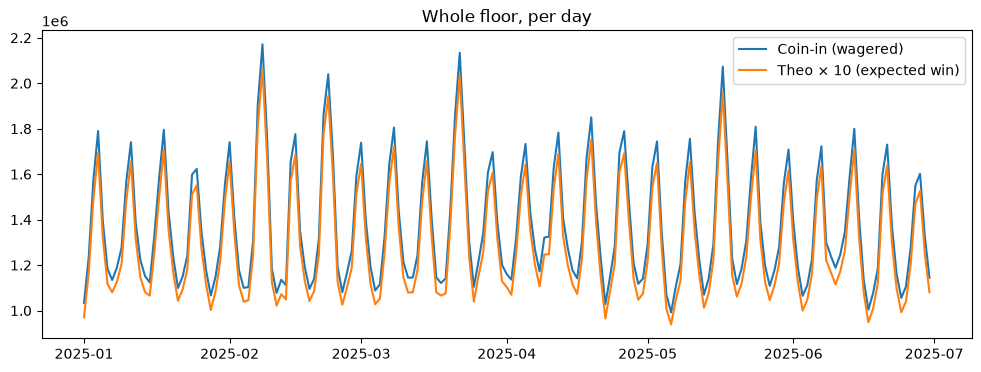

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_parquet("data/1_prepared_views/prepared_daily_view.parquet")
prop  = pd.read_parquet("data/1_prepared_views/property_day.parquet")
d = daily[daily["active"]]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(prop["gaming_date"], prop["coin_in_usd"], label="Coin-in (wagered)")
ax.plot(prop["gaming_date"], prop["theo_usd"] * 10, label="Theo × 10 (expected win)")
ax.set_title("Whole floor, per day")
ax.legend()
plt.show()

- **Spike 1:** Super Bowl weekend (Feb 7–9)
- **Spike 2:** Gilded Ace Winter Tournament (Feb 21–23)
- **Spike 3:** College basketball tournament opening rounds (Mar 20–22)
- **Spike 4:** EDC Las Vegas festival weekend (May 16–18)

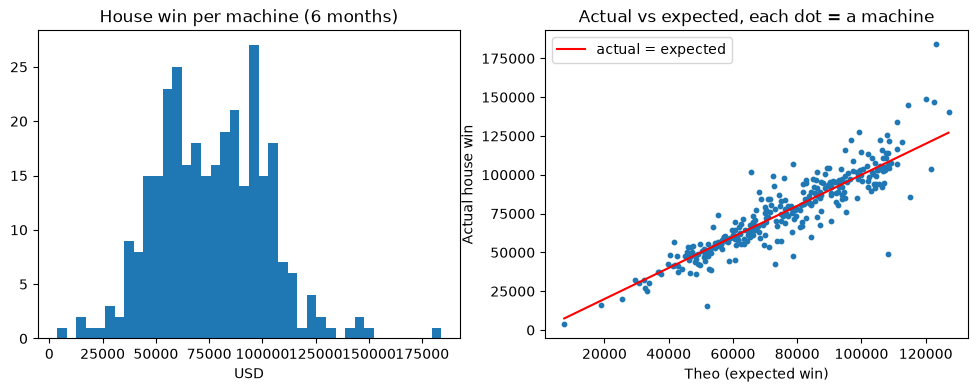

In [48]:
m = d.groupby("machine_id")[["house_win_usd", "theo_usd", "available_hours"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(m["house_win_usd"], bins=40)
axes[0].set_title("House win per machine (6 months)")
axes[0].set_xlabel("USD")

axes[1].scatter(m["theo_usd"], m["house_win_usd"], s=10)
lim = [m["theo_usd"].min(), m["theo_usd"].max()]
axes[1].plot(lim, lim, color="red", label="actual = expected")
axes[1].set_xlabel("Theo (expected win)")
axes[1].set_ylabel("Actual house win")
axes[1].set_title("Actual vs expected, each dot = a machine")
axes[1].legend()
plt.show()

In [49]:
import decimal
import pandas as pd

def load(path):
    """Read a parquet file and turn exact-decimal money columns into normal numbers."""
    df = pd.read_parquet(path)
    for c in df.columns:
        if df[c].dtype == object and df[c].dropna().map(type).eq(decimal.Decimal).any():
            df[c] = df[c].astype(float)
    return df

prop   = load("data/1_prepared_views/property_day.parquet")
events = load("data/4_context/events.parquet")
print(events[["name", "event_type", "start_date", "end_date", "announced_date"]])
print()

# Normal level = average for each weekday on days with no event
no_event = prop["events_active"].isna() | (prop["events_active"].astype(str).str.strip().isin(["", "0", "None", "[]"]))
normal = prop[no_event].groupby("local_weekday")[["coin_in_usd", "theo_usd"]].mean()

# Lift for each event vs a normal day with the same weekday
for _, e in events.iterrows():
    days = prop[(prop["gaming_date"] >= e["start_date"]) & (prop["gaming_date"] <= e["end_date"])]
    if days.empty:
        print(f"{e['name'][:40]:40} no matching days")
        continue
    base = normal.loc[days["local_weekday"]].sum()
    extra_theo = days["theo_usd"].sum() - base["theo_usd"]
    lift = days["coin_in_usd"].sum() / base["coin_in_usd"] - 1
    print(f"{e['name'][:40]:40} {len(days)} days  {lift:+.0%} coin-in   extra theo ≈ ${extra_theo:,.0f}")

                                           name          event_type  \
0                                           CES          convention   
1                        Super Bowl LIX weekend      sports_viewing   
2  College basketball tournament opening rounds      sports_viewing   
3                                     CinemaCon          convention   
4                                      NAB Show          convention   
5                EDC Las Vegas festival weekend            festival   
6             Gilded Ace Winter Slot Tournament  property_promotion   
7           Gilded Ace Locals Appreciation Week  property_promotion   

   start_date    end_date announced_date  
0  2025-01-07  2025-01-10     2024-01-12  
1  2025-02-07  2025-02-09     2024-01-01  
2  2025-03-20  2025-03-23     2024-12-01  
3  2025-03-31  2025-04-03     2024-04-15  
4  2025-04-05  2025-04-09     2024-04-20  
5  2025-05-16  2025-05-18     2024-05-20  
6  2025-02-21  2025-02-23     2025-01-20  
7  2025-06-09  2

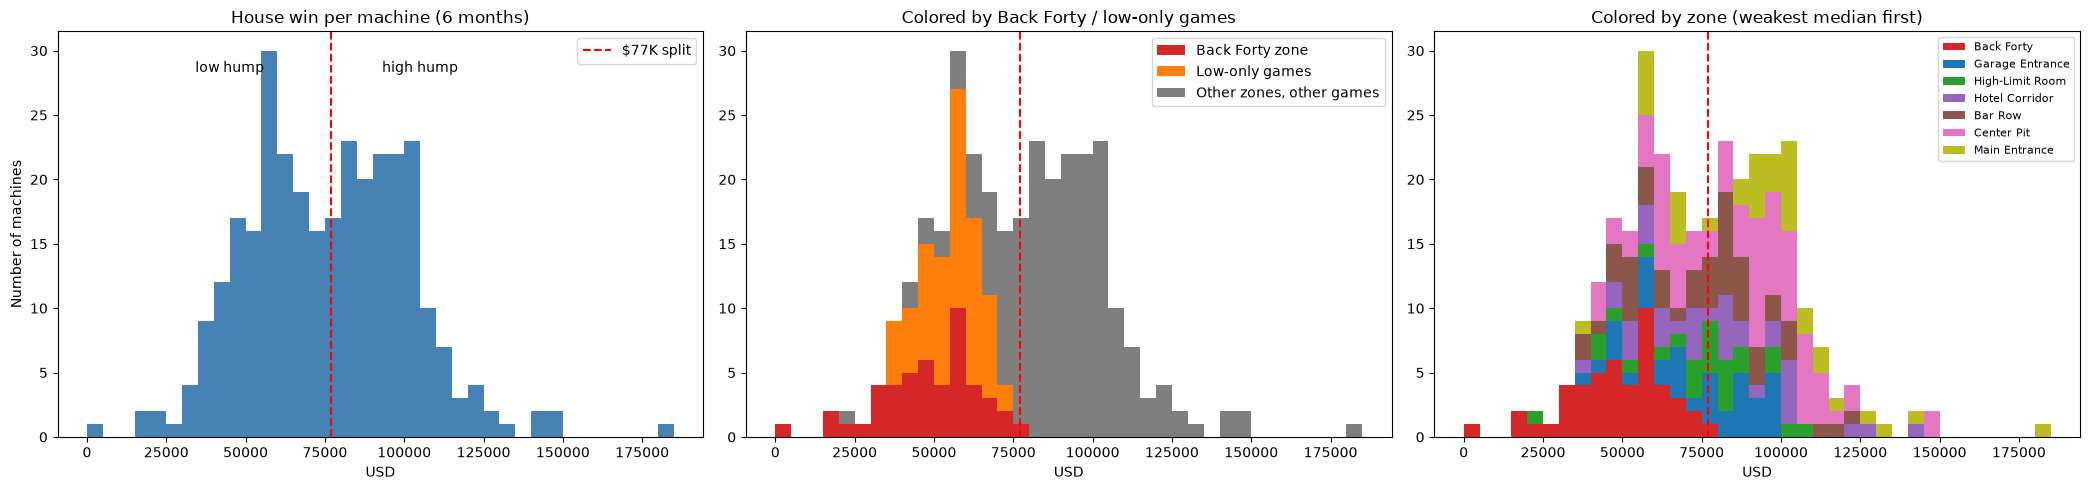

category
Other zones, other games    193
Low-only games               69
Back Forty zone              48
Name: count, dtype: int64


In [50]:
import matplotlib.pyplot as plt

daily = load("data/1_prepared_views/prepared_daily_view.parquet")
d = daily[daily["active"]]

m = d.groupby("machine_id").agg(
    house_win=("house_win_usd", "sum"),
    zone=("zone_name", "last"),
    theme=("theme", "first"),
)

low_games = ["Aurora Link", "Comet Cash", "Lucky Lanterns", "Royal Draw"]
m["category"] = "Other zones, other games"
m.loc[m["theme"].isin(low_games), "category"] = "Low-only games"
m.loc[m["zone"] == "Back Forty", "category"] = "Back Forty zone"

bins = range(0, 190_000, 5_000)
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# 1) Original histogram with the split line
axes[0].hist(m["house_win"], bins=bins, color="steelblue")
axes[0].axvline(77_000, color="red", linestyle="--", label="$77K split")
axes[0].text(45_000, axes[0].get_ylim()[1] * 0.9, "low hump", ha="center")
axes[0].text(105_000, axes[0].get_ylim()[1] * 0.9, "high hump", ha="center")
axes[0].set_title("House win per machine (6 months)")
axes[0].set_xlabel("USD")
axes[0].set_ylabel("Number of machines")
axes[0].legend()

# 2) Colored by Back Forty / low-only games / everything else
groups = ["Back Forty zone", "Low-only games", "Other zones, other games"]
colors = ["tab:red", "tab:orange", "tab:gray"]
axes[1].hist([m.loc[m["category"] == g, "house_win"] for g in groups],
             bins=bins, stacked=True, color=colors, label=groups)
axes[1].axvline(77_000, color="red", linestyle="--")
axes[1].set_title("Colored by Back Forty / low-only games")
axes[1].set_xlabel("USD")
axes[1].legend()

# 3) Colored by every zone, ordered from weakest to strongest median
zone_order = m.groupby("zone")["house_win"].median().sort_values().index
other_colors = ["tab:blue", "tab:green", "tab:purple", "tab:brown", "tab:pink", "tab:olive", "tab:cyan"]
zone_colors, i = {}, 0
for z in zone_order:
    if z == "Back Forty":
        zone_colors[z] = "tab:red"
    else:
        zone_colors[z] = other_colors[i]
        i += 1

axes[2].hist([m.loc[m["zone"] == z, "house_win"] for z in zone_order],
             bins=bins, stacked=True, label=zone_order,
             color=[zone_colors[z] for z in zone_order])
axes[2].axvline(77_000, color="red", linestyle="--")
axes[2].set_title("Colored by zone (weakest median first)")
axes[2].set_xlabel("USD")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(m["category"].value_counts())

          theme  configured_rtp volatility_class  min_bet_cents  max_bet_cents
     Comet Cash            0.92             high             25            100
 Lucky Lanterns            0.92              low             25            100
    Neon Nights            0.88             high             40            200
Prairie Thunder            0.89           medium             40            200
    Desert Gold            0.90           medium             50            200
 Classic Sevens            0.93              low            100            300
    Aurora Link            0.91           medium             50            400
 Jackpot Summit            0.88        very_high            100            500
     Royal Draw            0.95              low             25            500
 Platinum Reels            0.90             high            500           2500 



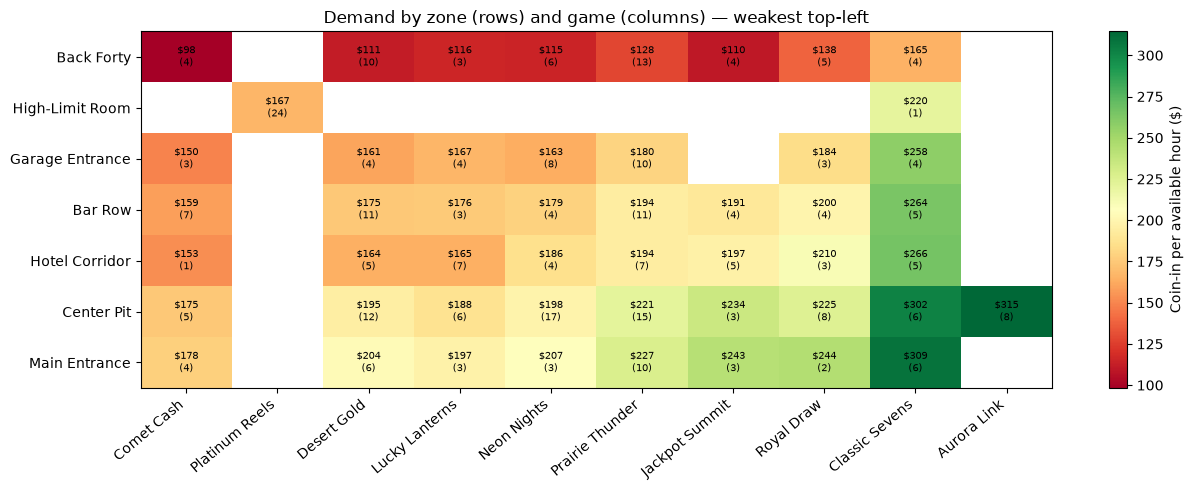

In [51]:
import matplotlib.pyplot as plt

daily = load("data/1_prepared_views/prepared_daily_view.parquet")
gm    = load("data/2_machine_decision/game_math.parquet")
d = daily[daily["active"]]

# 1) Game settings: are the low-only games just smaller-bet games?
print(gm[["theme", "configured_rtp", "volatility_class", "min_bet_cents", "max_bet_cents"]]
        .sort_values("max_bet_cents").to_string(index=False), "\n")

# 2) Fair demand measure: coin-in per available hour, for each zone x game
zg = d.groupby(["zone_name", "theme"]).agg(coin=("coin_in_usd", "sum"),
                                           hrs=("available_hours", "sum"),
                                           machines=("machine_id", "nunique"))
zg["rate"] = zg["coin"] / zg["hrs"]
rate = zg["rate"].unstack()
count = zg["machines"].unstack()

# Order zones and games from weakest to strongest
zone_rank = d.groupby("zone_name").apply(lambda g: g["coin_in_usd"].sum() / g["available_hours"].sum()).sort_values()
game_rank = d.groupby("theme").apply(lambda g: g["coin_in_usd"].sum() / g["available_hours"].sum()).sort_values()
rate = rate.loc[zone_rank.index, game_rank.index]
count = count.loc[zone_rank.index, game_rank.index]

# 3) Heatmap: each cell = $ wagered per available hour; number = machines in that cell
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(rate, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(rate.columns)), rate.columns, rotation=40, ha="right")
ax.set_yticks(range(len(rate.index)), rate.index)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        if pd.notna(rate.iat[i, j]):
            ax.text(j, i, f"${rate.iat[i, j]:,.0f}\n({int(count.iat[i, j])})",
                    ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Coin-in per available hour ($)")
ax.set_title("Demand by zone (rows) and game (columns) — weakest top-left")
plt.tight_layout()
plt.show()

In [52]:
g = d.groupby("theme").agg(
    machines=("machine_id", "nunique"),
    coin_in=("coin_in_usd", "sum"),
    house_win=("house_win_usd", "sum"),
    theo=("theo_usd", "sum"),
    rtp=("configured_rtp", "mean"),
    volatility=("volatility_class", "first"),
)
g["actual_hold"]   = g["house_win"] / g["coin_in"]
g["designed_hold"] = g["theo"] / g["coin_in"]          # = 1 - RTP
g["gap_pts"]       = (g["actual_hold"] - g["designed_hold"]) * 100
g["win_per_machine"] = g["house_win"] / g["machines"]

print(g.sort_values("gap_pts")[["machines", "rtp", "volatility", "designed_hold",
                                "actual_hold", "gap_pts", "win_per_machine"]].round(3))

                 machines   rtp volatility  designed_hold  actual_hold  \
theme                                                                    
Comet Cash             24  0.92       high           0.08        0.077   
Royal Draw             25  0.95        low           0.05        0.049   
Desert Gold            48  0.90     medium           0.10        0.099   
Lucky Lanterns         24  0.92        low           0.08        0.080   
Prairie Thunder        66  0.89     medium           0.11        0.110   
Classic Sevens         31  0.93        low           0.07        0.070   
Aurora Link             8  0.91     medium           0.09        0.091   
Neon Nights            42  0.88       high           0.12        0.121   
Jackpot Summit         18  0.88  very_high           0.12        0.124   
Platinum Reels         24  0.90       high           0.10        0.106   

                 gap_pts  win_per_machine  
theme                                      
Comet Cash        -0.31

In [53]:
machines = load("data/2_machine_decision/machines.parquet")
cal = load("data/2_machine_decision/calendar_day.parquet")

dd = d.merge(cal[["gaming_date", "scheduled_seconds"]], on="gaming_date")
ex = dd.groupby("theme").agg(
    machines=("machine_id", "nunique"),
    days_per_machine=("gaming_date", "count"),
    avail_hrs=("available_hours", "sum"),
    sched_hrs=("scheduled_seconds", lambda s: s.sum() / 3600),
    faults=("faults_opened", "sum"),
)
ex["days_per_machine"] = ex["days_per_machine"] / ex["machines"]
ex["availability"] = ex["avail_hrs"] / ex["sched_hrs"]
ex["faults_per_machine"] = ex["faults"] / ex["machines"]
print(ex[["machines", "days_per_machine", "availability", "faults_per_machine"]].round(3), "\n")

# Aurora Link machines individually
al = machines[machines["theme"] == "Aurora Link"]
print(al[["machine_id", "manufacturer", "install_date", "retire_date"]].to_string(index=False))

                 machines  days_per_machine  availability  faults_per_machine
theme                                                                        
Aurora Link             8            99.000         0.995               1.750
Classic Sevens         31           179.226         0.997               3.677
Comet Cash             24           181.000         0.995               5.083
Desert Gold            48           181.000         0.996               3.979
Jackpot Summit         18           181.000         0.997               3.167
Lucky Lanterns         24           181.000         0.995               5.125
Neon Nights            42           181.000         0.996               4.000
Platinum Reels         24           175.750         0.999               0.625
Prairie Thunder        66           181.000         0.996               4.288
Royal Draw             25           173.760         0.995               4.800 

machine_id manufacturer install_date retire_date
    M-2642   

In [54]:
placements = load("data/2_machine_decision/placements.parquet")

# Machines that left the floor during the period
retired = machines[machines["retire_date"].notna()]
print("Retired machines:")
print(retired[["machine_id", "manufacturer", "theme", "install_date", "retire_date"]].to_string(index=False), "\n")

# Which slots the Aurora Link machines went into, and who was there before
al_ids = machines.loc[machines["theme"] == "Aurora Link", "machine_id"]
al_slots = placements.loc[placements["machine_id"].isin(al_ids), "location_id"].unique()
history = placements[placements["location_id"].isin(al_slots)] \
            .merge(machines[["machine_id", "theme"]], on="machine_id") \
            .sort_values(["location_id", "effective_from_utc"])
print("History of the Aurora Link slots:")
print(history[["location_id", "machine_id", "theme", "effective_from_utc", "effective_to_utc"]].to_string(index=False))

Retired machines:
machine_id manufacturer          theme install_date retire_date
    M-1118    Ridgeline Platinum Reels   2019-02-16  2025-02-25
    M-1120    Ridgeline     Royal Draw   2018-02-16  2025-05-13 

History of the Aurora Link slots:
location_id machine_id       theme  effective_from_utc effective_to_utc
     L-51-1     M-2642 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-2     M-8743 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-3     M-8057 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-4     M-2799 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-5     M-7943 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-6     M-3101 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-7     M-7756 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-8     M-7487 Aurora Link 2025-03-24 13:00:00              NaT


In [55]:
# 1) Every machine installed during the six months
new = machines[machines["install_date"] >= pd.Timestamp("2025-01-01").date()]
print("Installed during the period:")
print(new[["machine_id", "manufacturer", "theme", "install_date"]].to_string(index=False), "\n")

# 2) Did the new Aurora Link bank pull play from other Center Pit machines?
cp = d[(d["zone_name"] == "Center Pit") & (~d["theme"].eq("Aurora Link"))].copy()
cp["period"] = (cp["gaming_date"] >= pd.Timestamp("2025-03-24").date()).map({False: "before Mar 24", True: "after Mar 24"})
rest = d[d["zone_name"] != "Center Pit"].copy()
rest["period"] = (rest["gaming_date"] >= pd.Timestamp("2025-03-24").date()).map({False: "before Mar 24", True: "after Mar 24"})

def rate(x):
    return x.groupby("period").apply(lambda g: g["coin_in_usd"].sum() / g["available_hours"].sum())

out = pd.DataFrame({"Center Pit (other games)": rate(cp), "Rest of floor": rate(rest)})
out.loc["change"] = out.loc["after Mar 24"] / out.loc["before Mar 24"] - 1
print("Coin-in per available hour:")
print(out.round(3))

Installed during the period:
machine_id manufacturer          theme install_date
    M-1532    Northwind Classic Sevens   2025-02-25
    M-2642      Halcyon    Aurora Link   2025-03-24
    M-2799      Halcyon    Aurora Link   2025-03-24
    M-3101      Halcyon    Aurora Link   2025-03-24
    M-5076      Halcyon     Royal Draw   2025-05-13
    M-7487      Halcyon    Aurora Link   2025-03-24
    M-7756      Halcyon    Aurora Link   2025-03-24
    M-7943      Halcyon    Aurora Link   2025-03-24
    M-8057      Halcyon    Aurora Link   2025-03-24
    M-8743      Halcyon    Aurora Link   2025-03-24 

Coin-in per available hour:
               Center Pit (other games)  Rest of floor
period                                                
after Mar 24                    207.743        173.265
before Mar 24                   219.396        186.024
change                           -0.053         -0.069


In [57]:
cases = [("M-1118", "M-1532", "2025-02-25"),   # Platinum Reels -> Classic Sevens
         ("M-1120", "M-5076", "2025-05-13")]   # old Royal Draw -> new Royal Draw

for old, new_id, swap in cases:
    swap = pd.Timestamp(swap).date()
    slot = d.loc[d["machine_id"] == new_id, "location_id"].iloc[0]
    zone = d.loc[d["machine_id"] == new_id, "zone_name"].iloc[0]

    s = d[d["location_id"] == slot]                               # the slot itself
    z = d[(d["zone_name"] == zone) & (d["location_id"] != slot)]  # rest of its zone = control

    def per_hr(x, col):
        b = x[x["gaming_date"] < swap]
        a = x[x["gaming_date"] >= swap]
        return (b[col].sum() / b["available_hours"].sum(),
                a[col].sum() / a["available_hours"].sum())

    sb, sa = per_hr(s, "coin_in_usd")
    zb, za = per_hr(z, "coin_in_usd")
    tb, ta = per_hr(s, "theo_usd")

    print(f"\n{old} -> {new_id}  (slot {slot}, {zone}, swap {swap})")
    print(f"  Slot coin-in/hr:  before ${sb:,.0f}  after ${sa:,.0f}  change {sa/sb-1:+.0%}")
    print(f"  Zone coin-in/hr:  before ${zb:,.0f}  after ${za:,.0f}  change {za/zb-1:+.0%}   (control)")
    print(f"  Slot theo/hr:     before ${tb:,.2f}  after ${ta:,.2f}  change {ta/tb-1:+.0%}")


M-1118 -> M-1532  (slot L-27-3, High-Limit Room, swap 2025-02-25)
  Slot coin-in/hr:  before $193  after $220  change +14%
  Zone coin-in/hr:  before $175  after $163  change -7%   (control)
  Slot theo/hr:     before $19.28  after $15.39  change -20%

M-1120 -> M-5076  (slot L-38-5, Back Forty, swap 2025-05-13)
  Slot coin-in/hr:  before $120  after $128  change +6%
  Zone coin-in/hr:  before $122  after $123  change +1%   (control)
  Slot theo/hr:     before $6.00  after $6.39  change +6%


In [58]:
md = load("data/2_machine_decision/machine_day.parquet")
gm = load("data/2_machine_decision/game_math.parquet")

# How much luck is normal for each machine (from bet sizes and game swinginess)
mdx = md[md["active"]].merge(gm[["config_id", "payout_multiplier_variance"]], on="config_id")
mdx["luck_var"] = mdx["sum_bet_squared"].astype(float) * mdx["payout_multiplier_variance"]
luck_sd = (mdx.groupby("machine_id")["luck_var"].sum() ** 0.5 / 100).rename("luck_sd")

# Actual vs expected per machine
lk = d.groupby("machine_id").agg(
    house_win=("house_win_usd", "sum"),
    theo=("theo_usd", "sum"),
    coin_in=("coin_in_usd", "sum"),
    rtp=("configured_rtp", "first"),
    theme=("theme", "first"),
    zone=("zone_name", "last"),
    volatility=("volatility_class", "first"),
).join(luck_sd)

lk["luck"]          = lk["house_win"] - lk["theo"]
lk["z"]             = lk["luck"] / lk["luck_sd"]
lk["actual_hold"]   = lk["house_win"] / lk["coin_in"]
lk["designed_hold"] = 1 - lk["rtp"]

# Check the luck math works: std should be near 1
print("z across all machines: mean", round(lk["z"].mean(), 2), " std", round(lk["z"].std(), 2), "\n")

cols = ["theme", "zone", "volatility", "designed_hold", "actual_hold", "luck", "z"]
print("Most unusual LOW results (possible leaks):")
print(lk.nsmallest(8, "z")[cols].round(3), "\n")
print("Most unusual HIGH results (very lucky):")
print(lk.nlargest(5, "z")[cols].round(3))

z across all machines: mean -0.07  std 1.09 

Most unusual LOW results (possible leaks):
                      theme             zone volatility  designed_hold  \
machine_id                                                               
M-1158          Desert Gold       Back Forty     medium           0.10   
M-1054      Prairie Thunder  Garage Entrance     medium           0.11   
M-1210           Royal Draw    Main Entrance        low           0.05   
M-1010          Desert Gold       Center Pit     medium           0.10   
M-1181           Comet Cash       Back Forty       high           0.08   
M-1201      Prairie Thunder   Hotel Corridor     medium           0.11   
M-1288       Jackpot Summit   Hotel Corridor  very_high           0.12   
M-1300           Comet Cash    Main Entrance       high           0.08   

            actual_hold       luck      z  
machine_id                                 
M-1158            0.030 -36164.750 -4.570  
M-1054            0.090 -14528.384 -2.

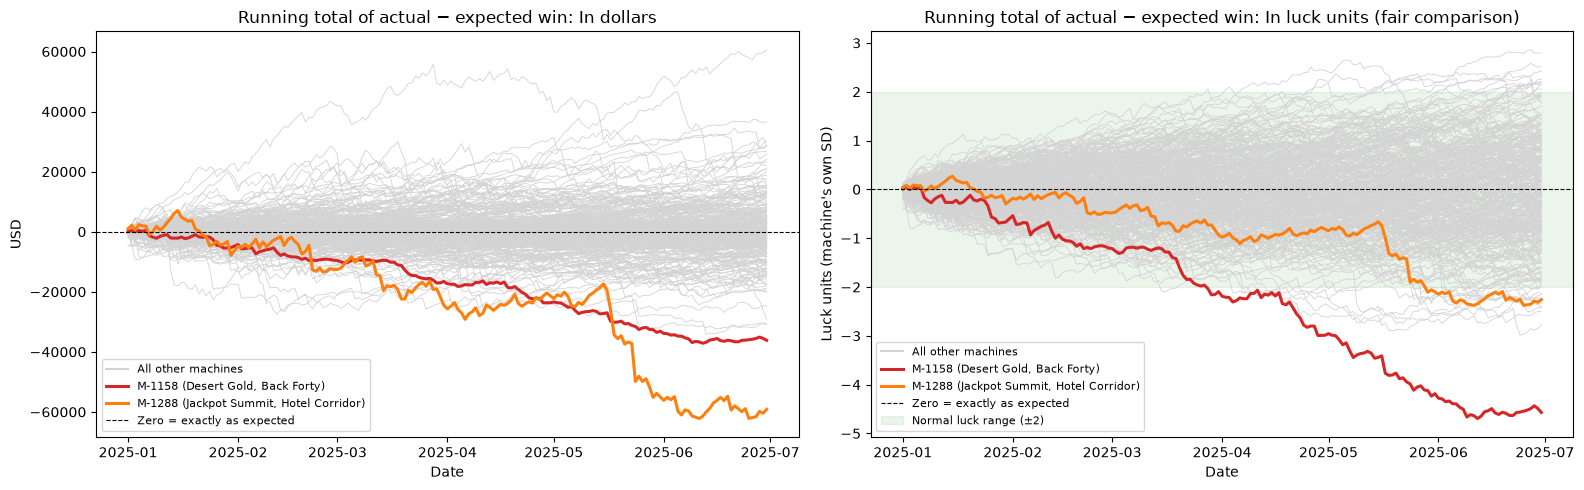

In [ ]:
import matplotlib.pyplot as plt

# Running total of actual − expected for every machine
dd = d.sort_values("gaming_date").copy()
dd["luck"] = dd["house_win_usd"] - dd["theo_usd"]
cum = dd.pivot_table(index="gaming_date", columns="machine_id", values="luck", aggfunc="sum").fillna(0).cumsum()
cum_z = cum / lk["luck_sd"]            # in units of each machine's normal luck (uses lk from the leak test)

highlight = {"M-1158": "tab:red",      # leak candidate (z -4.6)
             "M-1288": "tab:orange"}   # biggest dollar loss, but normal for its volatility (z -2.3)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, data, ylabel, title in [
        (axes[0], cum,   "USD",                          "In dollars"),
        (axes[1], cum_z, "Luck units (machine's own SD)", "In luck units (fair comparison)")]:
    ax.plot(data.index, data, color="lightgray", linewidth=0.6)
    ax.plot([], [], color="lightgray", label="All other machines")
    for mid, col in highlight.items():
        ax.plot(data.index, data[mid], color=col, linewidth=2.2,
                label=f"{mid} ({lk.loc[mid, 'theme']}, {lk.loc[mid, 'zone']})")
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, label="Zero = exactly as expected")
    ax.set_title(f"Running total of actual − expected win: {title}")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Date")

# Normal-luck band on the fair chart
axes[1].axhspan(-2, 2, color="green", alpha=0.08, label="Normal luck range (±2)")

for ax in axes:
    ax.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

Total downtime: 5,021 machine-hours
Lost expected win: $90,313  (0.38% of all expected win)



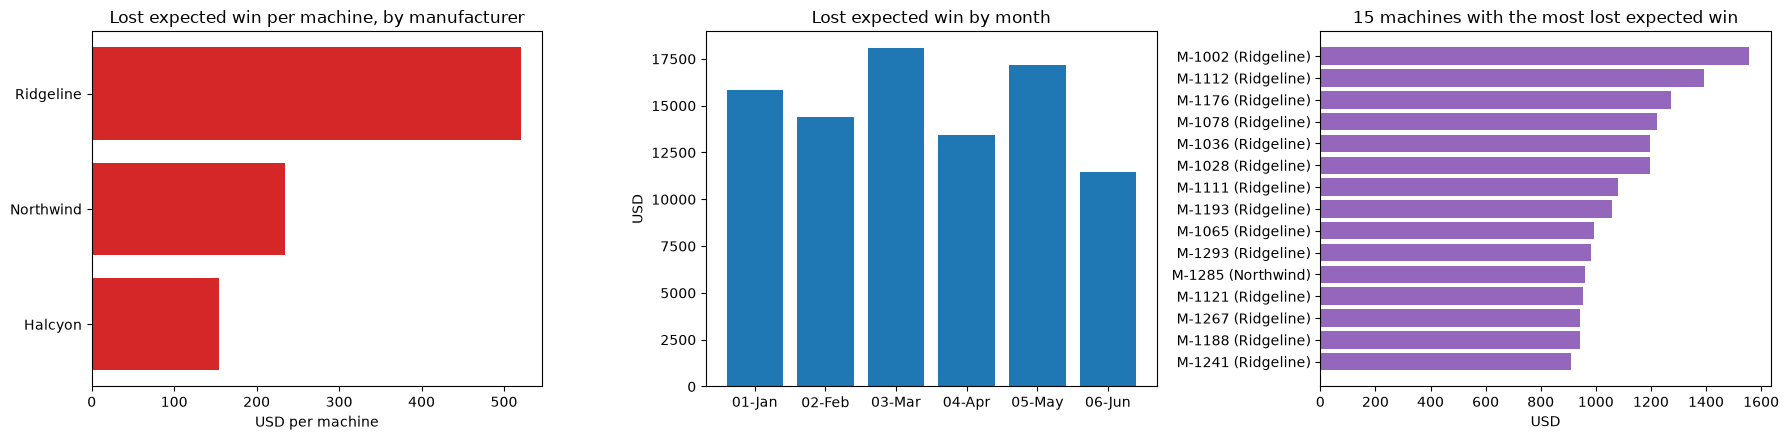

                       tickets  median_hrs_down  total_hrs_down
event_type                                                     
fault_repair              1207              3.2          4934.1
install                     10              6.0            60.0
move                         4              3.0            12.0
retire                       2              0.0             0.0
scheduled_maintenance        3              5.0            15.0


In [62]:
import matplotlib.pyplot as plt

daily = load("data/1_prepared_views/prepared_daily_view.parquet")
d = daily[daily["active"]]
cal = load("data/2_machine_decision/calendar_day.parquet")
ops = load("data/2_machine_decision/operations.parquet")

dt = d.merge(cal[["gaming_date", "scheduled_seconds"]], on="gaming_date").copy()
dt["down_hrs"] = dt["scheduled_seconds"] / 3600 - dt["available_hours"]

# Each machine's normal expected win per working hour
rate = dt.groupby("machine_id").apply(lambda g: g["theo_usd"].sum() / g["available_hours"].sum()).rename("theo_per_hr")
dt = dt.join(rate, on="machine_id")
dt["lost_theo"] = dt["down_hrs"] * dt["theo_per_hr"]

print(f"Total downtime: {dt['down_hrs'].sum():,.0f} machine-hours")
print(f"Lost expected win: ${dt['lost_theo'].sum():,.0f}  "
      f"({dt['lost_theo'].sum() / dt['theo_usd'].sum():.2%} of all expected win)\n")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) By manufacturer (preventive maintenance is bought per manufacturer)
by_mfr = dt.groupby("manufacturer").agg(lost=("lost_theo", "sum"), machines=("machine_id", "nunique"))
by_mfr["lost_per_machine"] = by_mfr["lost"] / by_mfr["machines"]
by_mfr = by_mfr.sort_values("lost_per_machine")
axes[0].barh(by_mfr.index, by_mfr["lost_per_machine"], color="tab:red")
axes[0].set_title("Lost expected win per machine, by manufacturer")
axes[0].set_xlabel("USD per machine")

# 2) By month
dt["month_name"] = pd.to_datetime(dt["gaming_date"]).dt.strftime("%m-%b")
by_month = dt.groupby("month_name")["lost_theo"].sum()
axes[1].bar(by_month.index, by_month.values, color="tab:blue")
axes[1].set_title("Lost expected win by month")
axes[1].set_ylabel("USD")

# 3) Top 15 machines
top = dt.groupby("machine_id").agg(lost=("lost_theo", "sum"), zone=("zone_name", "last"),
                                   mfr=("manufacturer", "first")).nlargest(15, "lost")
axes[2].barh([f"{i} ({r.mfr})" for i, r in top.iterrows()][::-1], top["lost"][::-1], color="tab:purple")
axes[2].set_title("15 machines with the most lost expected win")
axes[2].set_xlabel("USD")

plt.tight_layout()
plt.show()

# What kinds of tickets, and how long machines were down for each
ops["hours_down"] = (pd.to_datetime(ops["available_at_utc"]) - pd.to_datetime(ops["opened_at_utc"])).dt.total_seconds() / 3600
print(ops.groupby("event_type").agg(tickets=("operation_id", "count"),
                                    median_hrs_down=("hours_down", "median"),
                                    total_hrs_down=("hours_down", "sum")).round(1))

Players: 113,890
Total wagered: $163,804,870   Paid back: $148,219,409   Net player loss: $15,585,461
Players who came out ahead: 13.6%
Median player result: lost $72

Top 1% of losing players account for 15.7% of all losses
Top 5% of losing players account for 40.7% of all losses
Top 10% of losing players account for 52.8% of all losses
Top 20% of losing players account for 66.5% of all losses


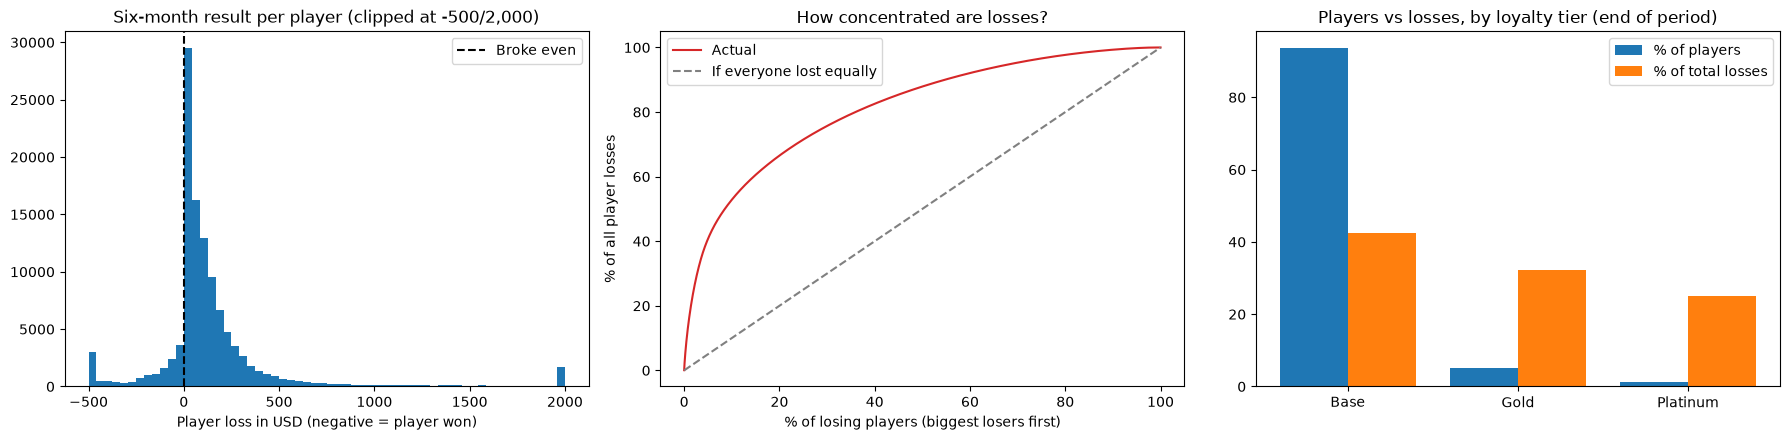

In [63]:
import matplotlib.pyplot as plt
import numpy as np

pp = load("data/1_prepared_views/player_period.parquet")

# One row per player for the full six months
pl = pp.groupby("player_id").agg(
    coin_in=("tracked_coin_in_usd", "sum"),
    payout=("tracked_payout_usd", "sum"),
    theo=("theo_usd", "sum"),
    visits=("observed_visits", "sum"),
    tier=("tier_end", "last"),
    age_band=("age_band", "first"),
    region=("home_region", "first"),
)
pl["player_loss"] = pl["coin_in"] - pl["payout"]      # positive = player lost money

n = len(pl)
print(f"Players: {n:,}")
print(f"Total wagered: ${pl['coin_in'].sum():,.0f}   Paid back: ${pl['payout'].sum():,.0f}   "
      f"Net player loss: ${pl['player_loss'].sum():,.0f}")
print(f"Players who came out ahead: {(pl['player_loss'] < 0).mean():.1%}")
print(f"Median player result: lost ${pl['player_loss'].median():,.0f}\n")

# Concentration: what share of all losses comes from the biggest losers?
losers = pl.loc[pl["player_loss"] > 0, "player_loss"].sort_values(ascending=False)
for pct in [0.01, 0.05, 0.10, 0.20]:
    k = max(1, int(len(losers) * pct))
    print(f"Top {pct:.0%} of losing players account for {losers.iloc[:k].sum() / losers.sum():.1%} of all losses")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Distribution of results (clipped so the middle is visible)
axes[0].hist(pl["player_loss"].clip(-500, 2000), bins=60, color="tab:blue")
axes[0].axvline(0, color="black", linestyle="--", label="Broke even")
axes[0].set_title("Six-month result per player (clipped at -$500 / $2,000)")
axes[0].set_xlabel("Player loss in USD (negative = player won)")
axes[0].legend()

# 2) Concentration curve
cum = losers.cumsum() / losers.sum()
share_players = np.arange(1, len(losers) + 1) / len(losers)
axes[1].plot(share_players * 100, cum * 100, color="tab:red", label="Actual")
axes[1].plot([0, 100], [0, 100], color="gray", linestyle="--", label="If everyone lost equally")
axes[1].set_title("How concentrated are losses?")
axes[1].set_xlabel("% of losing players (biggest losers first)")
axes[1].set_ylabel("% of all player losses")
axes[1].legend()

# 3) By loyalty tier
by_tier = pl.groupby("tier").agg(players=("player_loss", "size"), total_loss=("player_loss", "sum"))
by_tier["share_players"] = by_tier["players"] / by_tier["players"].sum() * 100
by_tier["share_loss"] = by_tier["total_loss"] / by_tier["total_loss"].sum() * 100
x = np.arange(len(by_tier))
axes[2].bar(x - 0.2, by_tier["share_players"], 0.4, label="% of players")
axes[2].bar(x + 0.2, by_tier["share_loss"], 0.4, label="% of total losses")
axes[2].set_xticks(x, by_tier.index)
axes[2].set_title("Players vs losses, by loyalty tier (end of period)")
axes[2].legend()

plt.tight_layout()
plt.show()

Comp cost from property_day:   $190,669
Comp cost from loyalty_ledger: $190,669

Share of comp cost by tier:
tier
Base        38.6%
Gold        49.7%
Platinum    11.7%
dtype: str


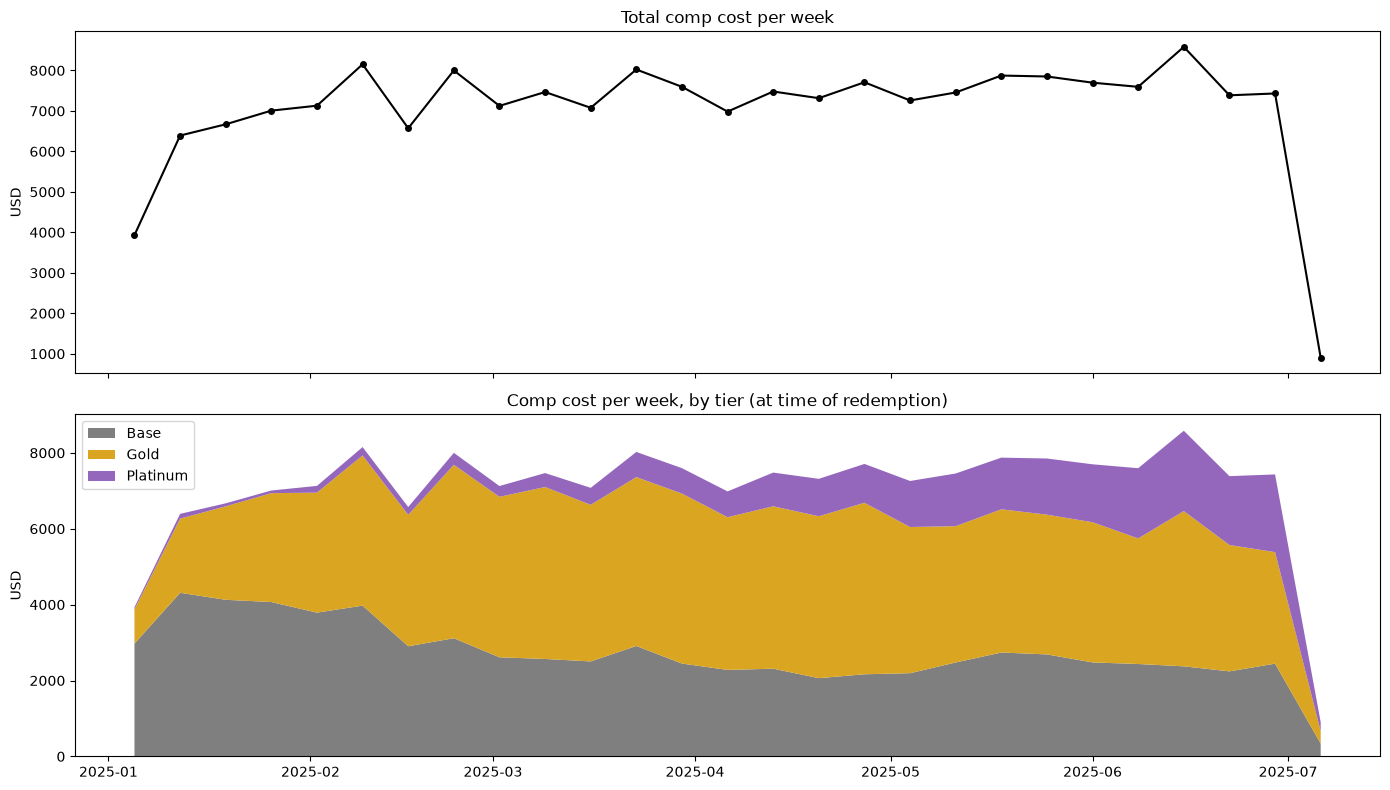

In [66]:
import matplotlib.pyplot as plt

prop = load("data/1_prepared_views/property_day.parquet")
led  = load("data/3_guests/loyalty_ledger.parquet")

# Keep only rows that cost the casino something (redeemed comps)
c = led[led["economic_cost_cents"].fillna(0) > 0].copy()
c["cost_usd"] = c["economic_cost_cents"] / 100

# UTC -> Las Vegas local time -> gaming day (6 a.m. to 6 a.m.)
local = pd.to_datetime(c["event_at_utc"], utc=True).dt.tz_convert("America/Los_Angeles")
c["gaming_date"] = (local - pd.Timedelta(hours=6)).dt.date
c["tier"] = c["tier_before"]

# Check: ledger total should be close to the property total
print(f"Comp cost from property_day:   ${prop['comp_cost_usd'].sum():,.0f}")
print(f"Comp cost from loyalty_ledger: ${c['cost_usd'].sum():,.0f}\n")

# Weekly total (property_day)
p = prop.set_index(pd.to_datetime(prop["gaming_date"]))
weekly_total = p["comp_cost_usd"].resample("W").sum()

# Weekly by tier (loyalty_ledger)
by_tier = c.pivot_table(index="gaming_date", columns="tier", values="cost_usd", aggfunc="sum").fillna(0)
by_tier.index = pd.to_datetime(by_tier.index)
tier_order = [t for t in ["Base", "Gold", "Platinum"] if t in by_tier.columns] + \
             [t for t in by_tier.columns if t not in ["Base", "Gold", "Platinum"]]
weekly_tier = by_tier[tier_order].resample("W").sum()

print("Share of comp cost by tier:")
print((weekly_tier.sum() / weekly_tier.sum().sum() * 100).round(1).astype(str) + "%")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# 1) Total comp cost per week
axes[0].plot(weekly_total.index, weekly_total.values, color="black", marker="o", markersize=4)
axes[0].set_title("Total comp cost per week")
axes[0].set_ylabel("USD")

# 2) Comp cost per week, stacked by tier
axes[1].stackplot(weekly_tier.index, weekly_tier.T.values, labels=weekly_tier.columns,
                  colors=["tab:gray", "goldenrod", "tab:purple"][:len(weekly_tier.columns)])
axes[1].set_title("Comp cost per week, by tier (at time of redemption)")
axes[1].set_ylabel("USD")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

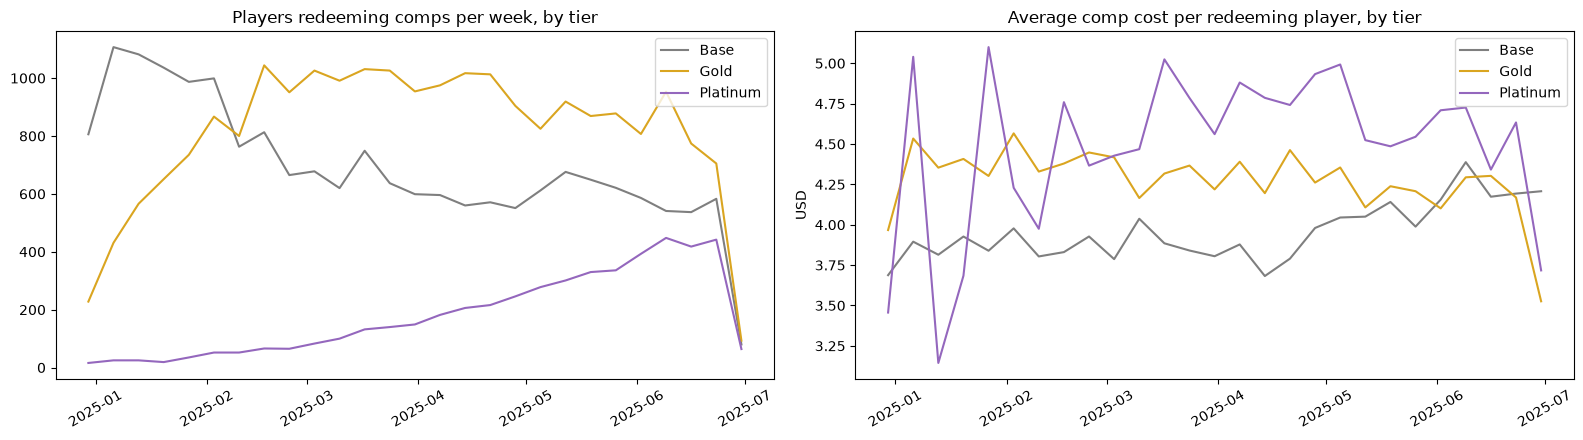

In [67]:
# Weekly: how many players redeemed in each tier, and how much each got on average
c["week"] = pd.to_datetime(c["gaming_date"]).dt.to_period("W").dt.start_time
w = c.groupby(["week", "tier"]).agg(players=("player_id", "nunique"), cost=("cost_usd", "sum")).reset_index()
w["cost_per_player"] = w["cost"] / w["players"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
colors = {"Base": "tab:gray", "Gold": "goldenrod", "Platinum": "tab:purple"}
for t, g in w.groupby("tier"):
    axes[0].plot(g["week"], g["players"], label=t, color=colors.get(t))
    axes[1].plot(g["week"], g["cost_per_player"], label=t, color=colors.get(t))
axes[0].set_title("Players redeeming comps per week, by tier")
axes[1].set_title("Average comp cost per redeeming player, by tier")
axes[1].set_ylabel("USD")
for ax in axes:
    ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [68]:
pp = load("data/1_prepared_views/player_period.parquet")
mo = pp.groupby("period_month").agg(points=("points_earned", "sum"),
                                    coin_in=("tracked_coin_in_usd", "sum"),
                                    comp_cost=("comp_cost_usd", "sum"),
                                    theo=("theo_usd", "sum"))
mo["points_per_100_bet"] = mo["points"] / mo["coin_in"] * 100
mo["comp_cost_pct_of_theo"] = mo["comp_cost"] / mo["theo"] * 100
print(mo[["points_per_100_bet", "comp_cost_pct_of_theo"]].round(3))

              points_per_100_bet  comp_cost_pct_of_theo
period_month                                           
2025-01                   99.880                  1.114
2025-02                   99.886                  1.204
2025-03                   99.889                  1.217
2025-04                   99.887                  1.242
2025-05                   99.885                  1.296
2025-06                   99.886                  1.317
